Importo todas las librerias que voy a usar

In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
class ImagenRGB():

    def __init__(self, img):
        self.img = img

    def mostrarImagen(self):
        plt.imshow(self.img)
        plt.title(titulo="Imagen")
        plt.axis("off")
        plt.show()

    def MostrarRGB(self):

        b=self.img[:,:,0]
        g=self.img[:,:,1]
        r=self.img[:,:,2]

        fig,axs=plt.subplots(2, 2, figsize=(8,8))

        axs[0,0].imshow(self.img)
        axs[0,0].set_title("RGB")
        axs[0,0].axis("off")

        axs[0,1].imshow(r,cmap="Reds")
        #axs[0,1].imshow(r)
        axs[0,1].set_title("Red")
        axs[0,1].axis("off")

        axs[1,0].imshow(g,cmap="Greens")
        #axs[1,0].imshow(g)
        axs[1,0].set_title("Green")
        axs[1,0].axis("off")

        axs[1,1].imshow(b, cmap="Blues")
        #axs[1,1].imshow(b)
        axs[1,1].set_title("Blue")
        axs[1,1].axis("off")

        plt.show()

    def normalizarImagen(self):
        return self.img/255

    def desnormalizarImagen(self):
        imagen=self,img*255
        return imagen.astype(np.uint8)


    def RGBaYIQ(self,imagen):
       M = np.array([[0.299, 0.587, 0.114],
                  [0.596, -0.275, -0.321],
                  [0.212, -0.523, 0.311]])

       R=imagen[:,:,2]
       G=imagen[:,:,1]
       B=imagen[:,:,0]

       alto,ancho=R.shape # obtengo las dimensiones de la matriz

       # Reorganizar la imagen: (alto*ancho, 3)
       rgb = np.stack([R, G, B],axis=-1).reshape(-1, 3) #une secuencias de matrices, 3 columnas y las filas las determina numpy por eso el  -1
       yiq = np.dot(rgb, M.T)

       # Volver a la forma original
       yiq = yiq.reshape(alto, ancho, 3)

       Y=yiq[:,:,0]
       I=yiq[:,:,1]
       Q=yiq[:,:,2]

       return Y,I,Q

    def mostrarYIQ(self,Y,I,Q):
        fig,axs=plt.subplots(2, 2,figsize=(8,8))

        axs[0,0].imshow(self.img)
        axs[0,0].set_title("RGB")
        axs[0,0].axis("off")

        axs[0,1].imshow(Y, cmap="gray")
        axs[0,1].set_title("Y (Luminancia)")
        axs[0,1].axis("off")

        axs[1,0].imshow(I, cmap="gray")
        axs[1,0].set_title("I (Crominancia)")
        axs[1,0].axis("off")

        axs[1,1].imshow(Q, cmap="gray")
        axs[1,1].set_title("Q (Crominancia)")
        axs[1,1].axis("off")

        plt.tight_layout()
        plt.show()

    def modificarYIQ(self,alpha,beta,y,i,q):
              y_new=alpha*y
              i_new=beta*i
              q_new=beta*q

              for i in range(y_new.shape[0]):
                for j in range(y_new.shape[1]):
                        if y_new[i,j]<=1:
                          flag1=True
                        else:
                          flag1=False
                          break

              for i_1 in range(i_new.shape[0]):
                for j_1 in range(i_new.shape[1]):
                        if i_new[i_1,j_1]<0.5957 and i_new[i_1,j_1]>-0.5957:
                           flag2=True
                        else:
                           flag2=False
                           break

              for i_2 in range(q_new.shape[0]):
               for j_2 in range(q_new.shape[1]):
                       if q_new[i_2,j_2]<0.5226 and q_new[i_2,j_2]>-0.5226:
                           flag3=True
                       else:
                           flag3=False
                           break

              flag_final=flag1 and flag2 and flag3

              return y_new,i_new,q_new,flag_final





    def YIQaRGB(self,Y,I,Q):
          matriz=np.array([[1, 0.9663, 0.6210],
                          [1, -0.2721, -0.6474],
                          [1, -1.1070, 1.7046]])

          alto, ancho = Y.shape
          yiq = np.stack([Y, I, Q], axis=-1).reshape(-1, 3)# Reorganizar en (alto*ancho, 3)
          rgb = np.dot(yiq, matriz.T)
          rgb = rgb.reshape(alto, ancho, 3)
          rgb = np.clip(rgb, 0, 1) # limita los valores entre 0 y 1

          return (rgb*255).astype(np.uint8)


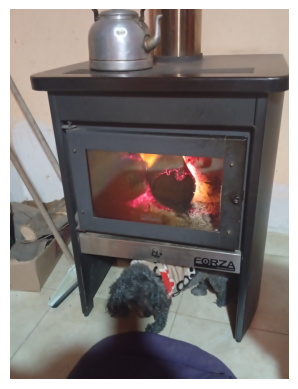

In [ ]:
img = cv2.imread('mi_img.jpg')
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
plt.imshow(img_rgb)
plt.axis("off")
plt.show()



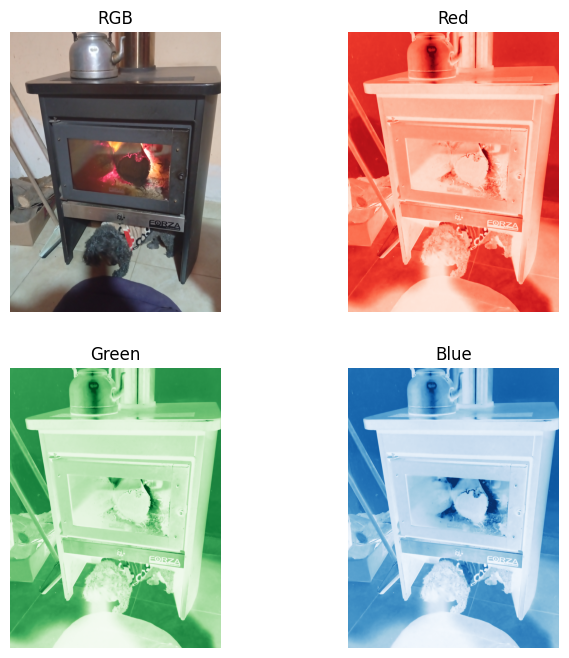

In [ ]:
mi_imagen =ImagenRGB(img_rgb)
mi_imagen.MostrarRGB()

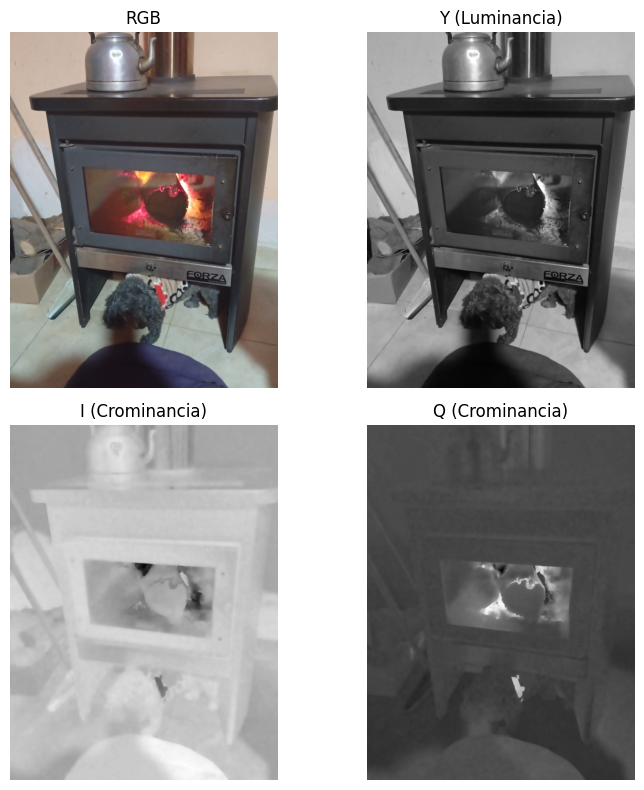

In [ ]:
img_norm=mi_imagen.normalizarImagen()
y,i,q=mi_imagen.RGBaYIQ(img_norm)
mi_imagen.mostrarYIQ(y,i,q)



¿El rango esta en el rango?: False


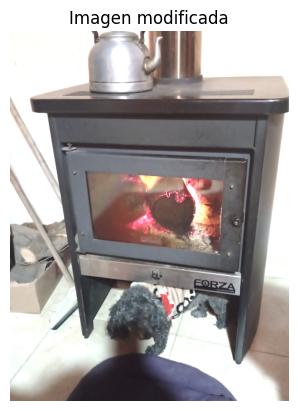

In [ ]:
alpha=1.5
beta=1
y_1,y_2,y_3,flag=mi_imagen.modificarYIQ(alpha,beta,y,i,q)
print("¿El rango esta en el rango?:",flag)
img_mod = mi_imagen.YIQaRGB(y_1, y_2,y_3)

plt.imshow(cv2.cvtColor(img_mod,cv2.COLOR_BGR2RGB))
plt.title("Imagen modificada")
plt.axis("off")
plt.show()

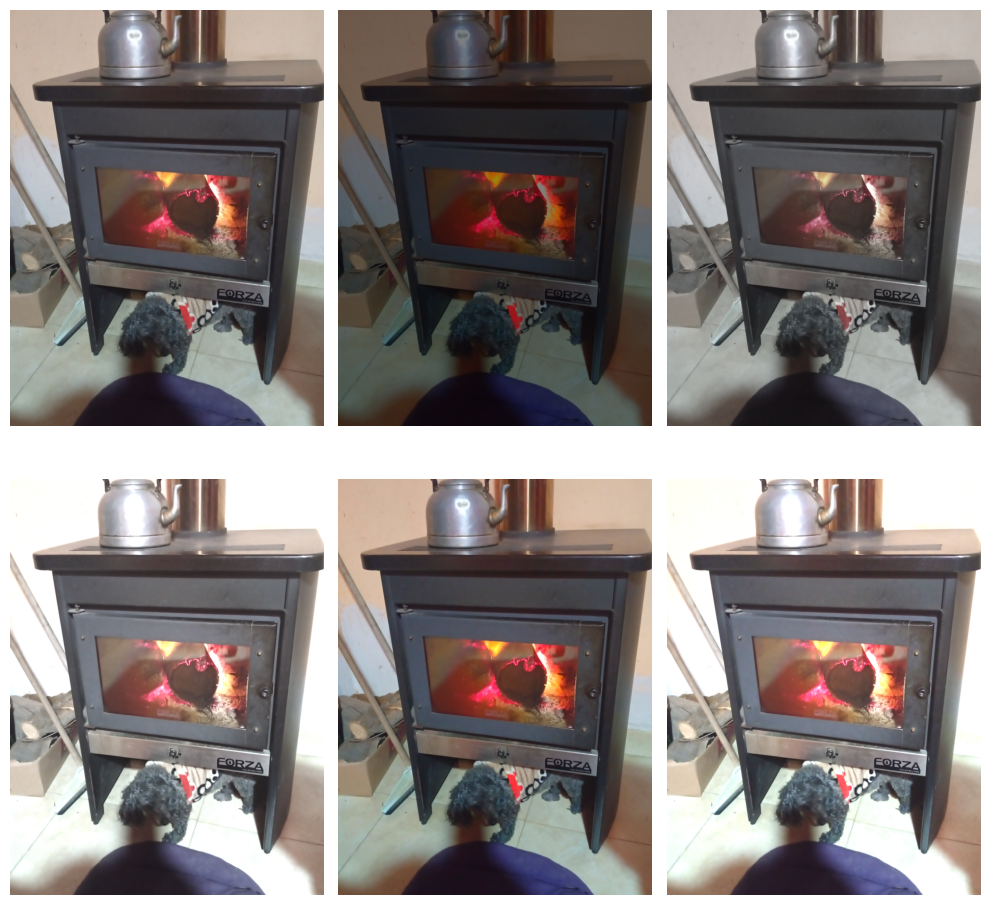

In [ ]:
lista=np.array([(1,1),(0.5,1),(1,0.5),(1.5,1),(1,1.5),(1.5,1.5)])
filas=2
columnas=3
fig,axes=plt.subplots(filas,columnas,figsize=(10,10))

for ax, (alpha, beta) in zip(axes.ravel(), lista): # zip devuelve un iterable de tuplas, axes.ravel() convierte el recorrido en 2D a 1D
    y_1, y_2, y_3, flag = mi_imagen.modificarYIQ(alpha, beta, y, i, q)
    img_mod2=mi_imagen.YIQaRGB(y_1,y_2,y_3)
    ax.imshow(cv2.cvtColor(img_mod2,cv2.COLOR_BGR2RGB), cmap='gray')
    ax.axis("off")

plt.tight_layout()
plt.show()